# U-Net ResNet34 Pretrained — Kvasir-SEG (Kaggle)

**Phạm vi:** Huấn luyện U-Net với **encoder ResNet34 pretrained ImageNet-1K**, decoder tự triển khai từ các file `unet_resnet34.py` và `unet.py` của nhóm; đánh giá trên Kvasir-SEG.

Notebook **không thực hiện Dataset Analysis trước khi train**. Chỉ có:
1. Nạp manifest + cặp ảnh–mask và kiểm tra tính khớp.
2. Chia Train/Validation/Test tương thích baseline U-Net.
3. Chuẩn hóa ImageNet, khởi tạo encoder pretrained.
4. Training, validation, checkpoint tốt nhất, test.
5. Dice/IoU/Precision/Recall theo từng ảnh, phân tích lỗi (FP/FN, kích thước polyp, chạm biên), Best/Worst cases.

**Quan trọng:** Chỉ có thể so sánh khoa học với U-Net thường khi dùng đúng các ID train/val/test, cách resize mask, threshold và giao thức đánh giá tương ứng.

## 1. Cấu hình và kiểm tra GPU
Giữ cùng budget với baseline U-Net: 256×256, batch=2, 50 epochs, Adam, BCE+Dice, early stopping patience=10, seed 42. 
Encoder được fine-tune từ đầu quá trình huấn luyện (không freeze). Sử dụng ImageNet normalization vì encoder pretrained yêu cầu.

In [1]:
from pathlib import Path
import os
import random
import json
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split

SEED = 42
IMAGE_SIZE = 256
BATCH_SIZE = 2
EPOCHS = 50
LEARNING_RATE = 1e-4
NUM_WORKERS = 2
PRETRAINED = True  # Bắt buộc True cho thí nghiệm pretrained
INPUT_ROOT = Path("/kaggle/input")
OUTPUT_DIR = Path("/kaggle/working/unet_resnet34_kvasir")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

seed_everything()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device} | PyTorch: {torch.__version__}")
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: GPU chưa bật. Kaggle > Settings > Accelerator > GPU.")

Device: cuda | PyTorch: 2.11.0+cu130
GPU: Tesla T4


## 2. Đọc Kvasir-SEG manifest CSV
Thêm vào Kaggle Input cả manifest `kvasir_seg_manifest.csv` và dataset ảnh/mask Kvasir-SEG. CSV chỉ chứa đường dẫn, không chứa ảnh.

In [2]:
MANIFEST_NAMES = {
    "kvasir_seg_manifest.csv",
    "kvasir-seg.csv",
    "kvasir_seg.csv",
}

manifest_candidates = sorted(
    p for p in INPUT_ROOT.rglob("*.csv")
    if p.name.lower() in MANIFEST_NAMES
)

if not manifest_candidates:
    raise FileNotFoundError(
        "Không tìm thấy CSV manifest trong /kaggle/input. "
        "Hãy Add Input file kvasir_seg_manifest.csv lên Kaggle."
    )

if len(manifest_candidates) > 1:
    print("Tìm thấy nhiều CSV:")
    for p in manifest_candidates:
        print(" -", p)
    raise RuntimeError(
        "Có nhiều manifest. Hãy giữ một file hoặc chỉ định MANIFEST_PATH thủ công."
    )

MANIFEST_PATH = manifest_candidates[0]
df = pd.read_csv(MANIFEST_PATH)

required_columns = {"name", "raw_image", "raw_mask"}
missing_columns = required_columns - set(df.columns)
if missing_columns:
    raise ValueError(f"CSV thiếu các cột bắt buộc: {sorted(missing_columns)}")

if df[list(required_columns)].isna().any().any():
    raise ValueError("CSV có giá trị rỗng trong name/raw_image/raw_mask.")

if df["name"].duplicated().any():
    raise ValueError("Cột name có ID trùng lặp.")

print("Manifest:", MANIFEST_PATH)
print("Rows:", len(df))
print("Columns:", df.columns.tolist())
display(df.head())

Manifest: /kaggle/input/datasets/namphmbuwu/kvasir-seg/kvasir_seg_manifest.csv
Rows: 1000
Columns: ['name', 'raw_image', 'raw_mask', 'orig_height', 'orig_width', 'fg_ratio_orig', 'fg_ratio_256', 'n_components', 'sha256_image', 'sha256_mask']


,name,raw_image,raw_mask,orig_height,orig_width,fg_ratio_orig,fg_ratio_256,n_components,sha256_image,sha256_mask
0,cju0qkwl35piu0993l0dewei2,data/raw/kvasir_seg/Kvasir-SEG/images/cju0qkwl...,data/raw/kvasir_seg/Kvasir-SEG/masks/cju0qkwl3...,529,622,0.282773,0.282822,1,71179abc4b011cc99bddb3344e3e114765b32bdf77e788...,11debb8496025566e43cda40a55720422b487d5f7892ff...
1,cju0qoxqj9q6s0835b43399p4,data/raw/kvasir_seg/Kvasir-SEG/images/cju0qoxq...,data/raw/kvasir_seg/Kvasir-SEG/masks/cju0qoxqj...,1070,1348,0.270595,0.270584,1,a2fbe43d8b079bcf3290f1daea4af382500eb2505289a7...,7f8035336e3e2dcc4445c560007c72999991d02e557d1f...
2,cju0qx73cjw570799j4n5cjze,data/raw/kvasir_seg/Kvasir-SEG/images/cju0qx73...,data/raw/kvasir_seg/Kvasir-SEG/masks/cju0qx73c...,529,619,0.318826,0.318756,1,abb709c70585be9c57dfbd98d59c06f4c2d0f7b6b81730...,cfe824e77a212c45ba839415b46c2b97707474e093565a...
3,cju0roawvklrq0799vmjorwfv,data/raw/kvasir_seg/Kvasir-SEG/images/cju0roaw...,data/raw/kvasir_seg/Kvasir-SEG/masks/cju0roawv...,528,622,0.108497,0.108749,3,6b3e0177e6c24d692456c9e1125e3d53f73c8372834a20...,f870a49fc6311e1c660a7647be892c5f206d5e15fefd74...
4,cju0rx1idathl0835detmsp84,data/raw/kvasir_seg/Kvasir-SEG/images/cju0rx1i...,data/raw/kvasir_seg/Kvasir-SEG/masks/cju0rx1id...,528,617,0.072768,0.072937,1,b004545e40c76da16ec2932905186353c05cb170295cef...,3d9769f509ec7f72a0bb4ed5d12242f07d7f5c2e8c7b84...


## 3. Ghép ảnh–mask từ Kaggle Input
Quét hai đường dẫn dataset bạn đang sử dụng, chọn nguồn có đầy đủ cặp ảnh–mask. Không cộng các bản sao Kvasir-SEG thành 2.000 mẫu.

In [3]:

from pathlib import Path

# Dataset locations
DATASET_ROOTS = [
    Path("/kaggle/input/datasets/namphmbuwu/kvasir-seg"),
    Path("/kaggle/input/datasets/bhavnagowda010/kvasir-seg-3"),
]

EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

def build_index(root, folder_names):
    index = {}

    for p in root.rglob("*"):
        if (
            p.is_file()
            and p.suffix.lower() in EXTENSIONS
            and p.parent.name.lower() in folder_names
        ):
            key = p.stem.lower()

            if key in index:
                raise ValueError(f"Duplicate file: {key}")

            index[key] = p

    return index


# Manifest keys
image_keys = df["raw_image"].map(
    lambda x: Path(str(x)).stem.lower()
)
mask_keys = df["raw_mask"].map(
    lambda x: Path(str(x)).stem.lower()
)

if not image_keys.equals(mask_keys):
    raise ValueError("Image-mask IDs do not match in manifest.")

expected = set(image_keys)

# Find the first complete dataset
selected = None

for root in DATASET_ROOTS:
    if not root.exists():
        print(f"Not found: {root}")
        continue

    images = build_index(root, {"images", "image"})
    masks = build_index(root, {"masks", "mask"})

    missing_images = expected - images.keys()
    missing_masks = expected - masks.keys()

    print(
        f"{root.name}: "
        f"images={len(images)}, masks={len(masks)}, "
        f"missing={len(missing_images) + len(missing_masks)}"
    )

    if not missing_images and not missing_masks:
        selected = (root, images, masks)
        break

if selected is None:
    raise FileNotFoundError(
        "Không tìm thấy dataset chứa đầy đủ 1000 ảnh và 1000 mask."
    )

DATASET_ROOT, images, masks = selected

# Build image-mask pairs
df["image_path"] = image_keys.map(images)
df["mask_path"] = mask_keys.map(masks)

pairs = list(zip(df["image_path"], df["mask_path"]))

assert len(pairs) == len(df)
assert all(i.stem.lower() == m.stem.lower() for i, m in pairs)

print("\n========== DATASET READY ==========")
print("Selected:", DATASET_ROOT)
print("Images:", len(images))
print("Masks:", len(masks))
print("Valid pairs:", len(pairs))
print("Status: PASSED")
print("Example:", pairs[0])


kvasir-seg: images=0, masks=0, missing=2000
kvasir-seg-3: images=1000, masks=1000, missing=0

========== DATASET READY ==========
Selected: /kaggle/input/datasets/bhavnagowda010/kvasir-seg-3
Images: 1000
Masks: 1000
Valid pairs: 1000
Status: PASSED
Example: (PosixPath('/kaggle/input/datasets/bhavnagowda010/kvasir-seg-3/Kvasir-SEG/images/cju0qkwl35piu0993l0dewei2.jpg'), PosixPath('/kaggle/input/datasets/bhavnagowda010/kvasir-seg-3/Kvasir-SEG/masks/cju0qkwl35piu0993l0dewei2.jpg'))


## 4. Train / Validation / Test — dùng split của U-Net thường

Ưu tiên sử dụng `split_manifest.csv` đã lưu từ mô hình U-Net thường (nếu bạn thêm file này vào Kaggle Input). Nếu không có, **tái tạo đúng phép chia của notebook U-Net thường trước đó** bằng hai lần `train_test_split(random_state=42)` trên cùng thứ tự manifest.

Không thay đổi tập Test dựa trên kết quả của mô hình.

In [4]:
# Ưu tiên split manifest từ U-Net baseline nếu đã được lưu.
split_candidates = sorted(INPUT_ROOT.rglob("split_manifest.csv"))

if len(split_candidates) > 1:
    raise RuntimeError(f"Có nhiều split_manifest.csv: {split_candidates}")

if len(split_candidates) == 1:
    split_path = split_candidates[0]
    split_frame = pd.read_csv(split_path)
    if not {"name", "split"}.issubset(split_frame.columns):
        raise ValueError("split_manifest.csv phải có cột name và split")
    if split_frame["name"].duplicated().any():
        raise ValueError("split_manifest.csv có tên ảnh trùng lặp")
    if set(split_frame["name"]) != set(df["name"]):
        raise ValueError("ID trong split_manifest.csv không khớp manifest dữ liệu")
    labels = split_frame.set_index("name")["split"].replace({"val": "validation"})
    df_split = df.copy()
    df_split["split"] = df_split["name"].map(labels)
    if df_split["split"].isna().any():
        raise ValueError("Không tìm được split cho một số ảnh")
    train_df = df_split[df_split["split"] == "train"].copy()
    val_df = df_split[df_split["split"] == "validation"].copy()
    test_df = df_split[df_split["split"] == "test"].copy()
    if len(train_df) + len(val_df) + len(test_df) != len(df):
        raise ValueError("Split có nhãn không hợp lệ")
    print("Using baseline split:", split_path)
else:
    # Tái lập đúng cách chia từ notebook U-Net thường.
    train_df, temp_df = train_test_split(
        df, test_size=0.20, random_state=SEED, shuffle=True
    )
    val_df, test_df = train_test_split(
        temp_df, test_size=0.50, random_state=SEED, shuffle=True
    )
    print("Regenerated baseline split with seed=42. "
          "Hãy đối chiếu split ID nếu baseline đã thay đổi.")

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

if any(set(a["name"]) & set(b["name"]) for a,b in
       [(train_df,val_df),(train_df,test_df),(val_df,test_df)]):
    raise ValueError("Data leakage: ID trùng giữa splits")

split_output = pd.concat([
    train_df.assign(split="train"),
    val_df.assign(split="validation"),
    test_df.assign(split="test"),
], ignore_index=True)
split_output[["name", "split"]].to_csv(OUTPUT_DIR / "split_manifest.csv", index=False)

print(f"Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")
print("Saved:", OUTPUT_DIR / "split_manifest.csv")

Regenerated baseline split with seed=42. Hãy đối chiếu split ID nếu baseline đã thay đổi.
Train: 800 | Val: 100 | Test: 100
Saved: /kaggle/working/unet_resnet34_kvasir/split_manifest.csv


## 5. Dataset và DataLoader — chuẩn hóa ImageNet
Resize ảnh RGB 256×256 bằng bilinear và mask bằng nearest neighbor, giống baseline. 
Khác biệt bắt buộc: encoder ResNet34 pretrained sử dụng mean/std ImageNet.

In [5]:
RESAMPLING = Image.Resampling if hasattr(Image, "Resampling") else Image
IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
IMAGENET_STD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

class KvasirSegDataset(Dataset):
    def __init__(self, frame, image_size=IMAGE_SIZE):
        self.frame = frame.reset_index(drop=True)
        self.image_size = image_size

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        row = self.frame.iloc[index]

        with Image.open(row["image_path"]) as img:
            image = img.convert("RGB").resize(
                (self.image_size, self.image_size),
                RESAMPLING.BILINEAR
            )

        with Image.open(row["mask_path"]) as msk:
            mask = msk.convert("L").resize(
                (self.image_size, self.image_size),
                RESAMPLING.NEAREST
            )

        image = np.asarray(image, dtype=np.float32) / 255.0
        mask = np.asarray(mask, dtype=np.uint8)
        mask = (mask >= 128).astype(np.float32)

        image = torch.from_numpy(image).permute(2, 0, 1).contiguous()
        image = (image - IMAGENET_MEAN) / IMAGENET_STD
        mask = torch.from_numpy(mask[None, ...]).contiguous()

        return image, mask, str(row["name"])

train_dataset = KvasirSegDataset(train_df)
val_dataset = KvasirSegDataset(val_df)
test_dataset = KvasirSegDataset(test_df)

loader_options = {
    "batch_size": BATCH_SIZE,
    "num_workers": NUM_WORKERS,
    "pin_memory": device.type == "cuda",
    "persistent_workers": NUM_WORKERS > 0,
}

train_loader = DataLoader(
    train_dataset, shuffle=True, **loader_options
)
val_loader = DataLoader(
    val_dataset, shuffle=False, **loader_options
)
test_loader = DataLoader(
    test_dataset, shuffle=False, **loader_options
)

images, masks, names = next(iter(train_loader))
print("Image batch:", tuple(images.shape))
print("Mask batch :", tuple(masks.shape))
print("Mask values:", torch.unique(masks))

Image batch: (2, 3, 256, 256)
Mask batch : (2, 1, 256, 256)
Mask values: tensor([0., 1.])


## 6. Kiến trúc U-Net ResNet34 pretrained (đúng theo mã bạn gửi)

Encoder dùng `torchvision.models.resnet34(weights=ResNet34_Weights.IMAGENET1K_V1)`. 
Decoder `ConvTranspose2d + skip + DoubleConv` là phần nhóm tự triển khai.
Toàn bộ encoder/decoder có `requires_grad=True`.

**Lưu ý về pretrained weights:** Lần chạy đầu cần tải trọng số ImageNet (Kaggle Internet ON hoặc thêm file trọng số vào Input/cache). Notebook dừng nếu không thể tải; tuyệt đối không tự chuyển sang `pretrained=False` rồi ghi kết quả là pretrained.

In [6]:
"""U-Net với encoder ResNet34 từ torchvision và decoder tự cài đặt."""

import torch
from torch import nn
from torch.nn import functional as F
from torchvision.models import ResNet34_Weights, resnet34

class DoubleConv(nn.Module):
    """Hai lần Conv 3x3 + ReLU, giữ nguyên kích thước không gian."""

    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.layers(x)


class _DecoderBlock(nn.Module):
    """Upsampling, ghép skip nếu có, rồi hai Conv 3x3 + ReLU."""

    def __init__(self, in_channels: int, skip_channels: int, out_channels: int):
        super().__init__()
        self.up = nn.ConvTranspose2d(in_channels, out_channels, kernel_size=2, stride=2)
        self.conv = DoubleConv(out_channels + skip_channels, out_channels)

    def forward(
        self,
        x: torch.Tensor,
        output_size: tuple[int, int],
        skip: torch.Tensor | None = None,
    ) -> torch.Tensor:
        x = self.up(x)
        # ResNet làm tròn lên khi giảm kích thước: ảnh lẻ có thể lệch 1 pixel.
        if x.shape[-2:] != output_size:
            x = F.interpolate(x, size=output_size, mode="bilinear", align_corners=False)
        if skip is not None:
            x = torch.cat([skip, x], dim=1)
        return self.conv(x)


class UNetResNet34(nn.Module):
    """Nhận ảnh RGB (B, 3, H, W), trả logits (B, out_channels, H, W).

    Mặc định encoder nạp ResNet34_Weights.IMAGENET1K_V1, decoder khởi tạo
    ngẫu nhiên; toàn bộ encoder được phép học tiếp. Lần đầu cần tải trọng
    số nếu cache chưa có. pretrained=False không tải trọng số, dùng cho
    kiểm thử hoặc ablation encoder khởi tạo ngẫu nhiên.

    Đầu vào cần chuẩn hóa ImageNet; H và W >= 32. Với batch một ảnh rất
    nhỏ, BatchNorm của encoder cần model.eval() khi suy luận.
    """

    def __init__(self, pretrained: bool = True, out_channels: int = 1):
        super().__init__()
        if not isinstance(pretrained, bool):
            raise ValueError("pretrained phải là bool")
        if not isinstance(out_channels, int) or isinstance(out_channels, bool) or out_channels < 1:
            raise ValueError("out_channels phải là số nguyên dương")

        weights = ResNet34_Weights.IMAGENET1K_V1 if pretrained else None
        self.encoder = resnet34(weights=weights)
        # Chỉ dùng các tầng đặc trưng, bỏ head phân loại ImageNet.
        self.encoder.avgpool = nn.Identity()
        self.encoder.fc = nn.Identity()

        self.dec4 = _DecoderBlock(512, 256, 256)
        self.dec3 = _DecoderBlock(256, 128, 128)
        self.dec2 = _DecoderBlock(128, 64, 64)
        self.dec1 = _DecoderBlock(64, 64, 32)
        # Stem đã giảm ảnh xuống H/2: cần thêm một bước về kích thước gốc.
        self.dec0 = _DecoderBlock(32, 0, 16)
        self.head = nn.Conv2d(16, out_channels, kernel_size=1)
        # Không khởi tạo lại toàn mạng để giữ nguyên trọng số pretrained.

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        if x.ndim != 4 or x.shape[1] != 3:
            raise ValueError("Đầu vào phải có dạng (B, 3, H, W)")
        if min(x.shape[-2:]) < 32:
            raise ValueError("H và W phải >= 32 cho encoder ResNet34")
        output_size = x.shape[-2:]
        enc = self.encoder
        e0 = enc.relu(enc.bn1(enc.conv1(x)))
        e1 = enc.layer1(enc.maxpool(e0))
        e2 = enc.layer2(e1)
        e3 = enc.layer3(e2)
        e4 = enc.layer4(e3)

        x = self.dec4(e4, e3.shape[-2:], e3)
        x = self.dec3(x, e2.shape[-2:], e2)
        x = self.dec2(x, e1.shape[-2:], e1)
        x = self.dec1(x, e0.shape[-2:], e0)
        x = self.dec0(x, output_size)
        return self.head(x)


# Khởi tạo đúng encoder pretrained; nếu chưa có weights cache,
# Kaggle cần Internet ON hoặc add file weights đúng cache.
try:
    model = UNetResNet34(pretrained=PRETRAINED).to(device)
except Exception as exc:
    raise RuntimeError(
        "Không khởi tạo được ResNet34 pretrained. "
        "Bật Kaggle Internet trong Settings hoặc nạp trước đúng "
        "trọng số IMAGENET1K_V1 vào torch cache. "
        "Không đổi pretrained=False để thay thế."
    ) from exc

num_parameters = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Trainable parameters: {num_parameters:,}")
print("Encoder pretrained:", PRETRAINED)
print("Encoder fine-tuning:", all(p.requires_grad for p in model.encoder.parameters()))

with torch.no_grad():
    sample_logits = model(images[:1].to(device))
print("Output shape:", tuple(sample_logits.shape))
assert sample_logits.shape == (1, 1, IMAGE_SIZE, IMAGE_SIZE)

Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth


100%|██████████| 83.3M/83.3M [00:00<00:00, 172MB/s] 


Trainable parameters: 24,348,449
Encoder pretrained: True
Encoder fine-tuning: True
Output shape: (1, 1, 256, 256)


## 7. Loss, optimizer và metrics
Giữ giao thức đánh giá baseline: **0.5 BCE + 0.5 soft Dice**, Adam, ReduceLROnPlateau, threshold=0.5, **micro Dice/IoU** cho toàn bộ pixel. Thêm per-image Dice/IoU để đánh giá lỗi.

In [7]:
class BCEDiceLoss(nn.Module):
    def __init__(self, bce_weight=0.5, dice_weight=0.5, eps=1e-7):
        super().__init__()
        self.bce = nn.BCEWithLogitsLoss()
        self.bce_weight = bce_weight
        self.dice_weight = dice_weight
        self.eps = eps

    def forward(self, logits, targets):
        bce_loss = self.bce(logits, targets)

        probs = torch.sigmoid(logits)
        dims = (1, 2, 3)
        intersection = (probs * targets).sum(dim=dims)
        denominator = probs.sum(dim=dims) + targets.sum(dim=dims)
        dice = (2 * intersection + self.eps) / (denominator + self.eps)
        dice_loss = 1 - dice.mean()

        return (
            self.bce_weight * bce_loss
            + self.dice_weight * dice_loss
        )


criterion = BCEDiceLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="max", factor=0.5, patience=4
)

def run_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)

    total_loss = 0.0
    total_samples = 0
    intersection_total = 0.0
    prediction_total = 0.0
    target_total = 0.0

    for images, masks, _ in loader:
        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            logits = model(images)
            loss = criterion(logits, masks)

            if training:
                loss.backward()
                optimizer.step()

        batch_size = images.size(0)
        total_loss += loss.item() * batch_size
        total_samples += batch_size

        predictions = (torch.sigmoid(logits) >= 0.5).float()
        intersection_total += (predictions * masks).sum().item()
        prediction_total += predictions.sum().item()
        target_total += masks.sum().item()

    eps = 1e-7
    dice = (2 * intersection_total + eps) / (
        prediction_total + target_total + eps
    )
    iou = (intersection_total + eps) / (
        prediction_total + target_total - intersection_total + eps
    )

    return {
        "loss": total_loss / max(total_samples, 1),
        "dice": dice,
        "iou": iou,
    }

## 8. Huấn luyện và lưu checkpoint tốt nhất

Checkpoint được chọn theo Validation Dice. Early stopping dừng nếu Validation Dice không cải thiện trong 10 epoch liên tiếp.

In [8]:
BEST_MODEL_PATH = OUTPUT_DIR / "best_unet_resnet34_kvasir.pt"
HISTORY_PATH = OUTPUT_DIR / "training_history.csv"
EARLY_STOPPING_PATIENCE = 10

history = []
best_val_dice = -1.0
epochs_without_improvement = 0

for epoch in range(1, EPOCHS + 1):
    start_time = time.time()

    train_metrics = run_epoch(model, train_loader, optimizer)
    val_metrics = run_epoch(model, val_loader)

    scheduler.step(val_metrics["dice"])
    current_lr = optimizer.param_groups[0]["lr"]

    row = {
        "epoch": epoch,
        "lr": current_lr,
        "train_loss": train_metrics["loss"],
        "train_dice": train_metrics["dice"],
        "train_iou": train_metrics["iou"],
        "val_loss": val_metrics["loss"],
        "val_dice": val_metrics["dice"],
        "val_iou": val_metrics["iou"],
    }
    history.append(row)
    pd.DataFrame(history).to_csv(HISTORY_PATH, index=False)

    improved = val_metrics["dice"] > best_val_dice
    if improved:
        best_val_dice = val_metrics["dice"]
        epochs_without_improvement = 0

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "best_val_dice": best_val_dice,
                "config": {
                    "image_size": IMAGE_SIZE,
                    "architecture": "UNetResNet34",
                    "encoder": "resnet34",
                    "pretrained": PRETRAINED,
                    "normalization": "imagenet",
                    "batch_size": BATCH_SIZE,
                    "learning_rate": LEARNING_RATE,
                    "seed": SEED,
                },
            },
            BEST_MODEL_PATH,
        )
    else:
        epochs_without_improvement += 1

    elapsed = time.time() - start_time
    print(
        f"Epoch {epoch:03d}/{EPOCHS} | "
        f"Train Loss {train_metrics['loss']:.4f} | "
        f"Train Dice {train_metrics['dice']:.4f} | "
        f"Val Loss {val_metrics['loss']:.4f} | "
        f"Val Dice {val_metrics['dice']:.4f} | "
        f"Val IoU {val_metrics['iou']:.4f} | "
        f"LR {current_lr:.2e} | {elapsed:.1f}s"
        + (" | BEST" if improved else "")
    )

    if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
        print("Early stopping: validation Dice không cải thiện.")
        break

print("\nBest validation Dice:", round(best_val_dice, 4))
print("Best checkpoint:", BEST_MODEL_PATH)

Epoch 001/50 | Train Loss 0.4332 | Train Dice 0.5091 | Val Loss 0.2314 | Val Dice 0.8026 | Val IoU 0.6703 | LR 1.00e-04 | 67.2s | BEST
Epoch 002/50 | Train Loss 0.2059 | Train Dice 0.8167 | Val Loss 0.2158 | Val Dice 0.8002 | Val IoU 0.6669 | LR 1.00e-04 | 24.1s
Epoch 003/50 | Train Loss 0.1534 | Train Dice 0.8646 | Val Loss 0.2084 | Val Dice 0.8096 | Val IoU 0.6801 | LR 1.00e-04 | 25.4s | BEST
Epoch 004/50 | Train Loss 0.1127 | Train Dice 0.9003 | Val Loss 0.1820 | Val Dice 0.8636 | Val IoU 0.7600 | LR 1.00e-04 | 26.0s | BEST
Epoch 005/50 | Train Loss 0.1042 | Train Dice 0.9081 | Val Loss 0.1708 | Val Dice 0.8634 | Val IoU 0.7597 | LR 1.00e-04 | 25.2s
Epoch 006/50 | Train Loss 0.0887 | Train Dice 0.9200 | Val Loss 0.1666 | Val Dice 0.8625 | Val IoU 0.7583 | LR 1.00e-04 | 25.0s
Epoch 007/50 | Train Loss 0.0769 | Train Dice 0.9333 | Val Loss 0.1819 | Val Dice 0.8456 | Val IoU 0.7325 | LR 1.00e-04 | 25.3s
Epoch 008/50 | Train Loss 0.0797 | Train Dice 0.9298 | Val Loss 0.1529 | Val Dice 0

## 9. Đánh giá Test — chỉ sau khi chọn checkpoint tốt nhất từ Validation
Đo **Test Loss, Micro Dice, Micro IoU** theo cùng định nghĩa với U-Net thường.

In [9]:
checkpoint = torch.load(BEST_MODEL_PATH, map_location=device, weights_only=True)
model.load_state_dict(checkpoint["model_state_dict"])

test_metrics = run_epoch(model, test_loader)

results = {
    "best_epoch": int(checkpoint["epoch"]),
    "best_validation_dice": float(checkpoint["best_val_dice"]),
    "test_loss": float(test_metrics["loss"]),
    "test_dice": float(test_metrics["dice"]),
    "test_iou": float(test_metrics["iou"]),
    "test_samples": int(len(test_dataset)),
}

with open(OUTPUT_DIR / "test_metrics.json", "w") as f:
    json.dump(results, f, indent=2)

print("========== TEST RESULTS ==========")
for key, value in results.items():
    print(f"{key}: {value}")

========== TEST RESULTS ==========
best_epoch: 20
best_validation_dice: 0.8873780950478783
test_loss: 0.13859861265867948
test_dice: 0.8912178945266551
test_iou: 0.8037809143268947
test_samples: 100


## 10. Biểu đồ quá trình huấn luyện

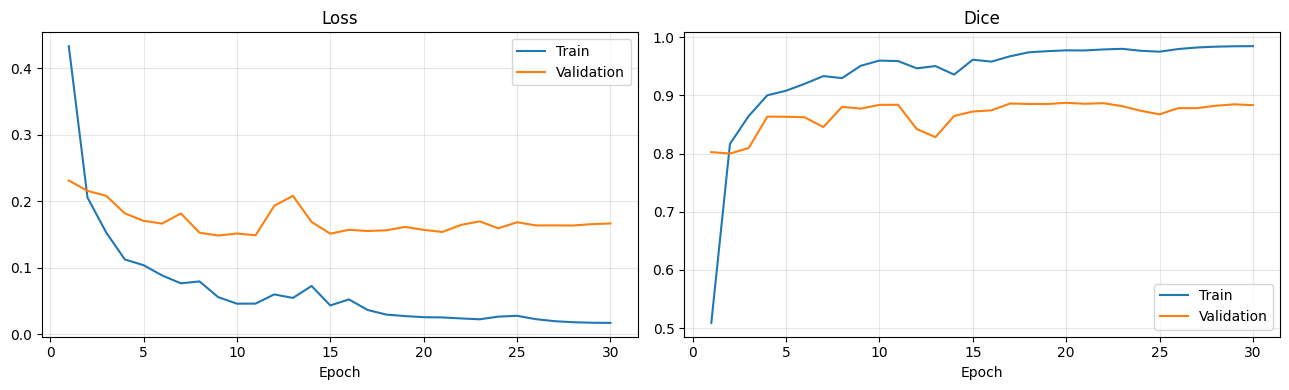

In [10]:
history_df = pd.read_csv(HISTORY_PATH)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(history_df["epoch"], history_df["train_loss"], label="Train")
axes[0].plot(history_df["epoch"], history_df["val_loss"], label="Validation")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(history_df["epoch"], history_df["train_dice"], label="Train")
axes[1].plot(history_df["epoch"], history_df["val_dice"], label="Validation")
axes[1].set_title("Dice")
axes[1].set_xlabel("Epoch")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "training_curves.png", dpi=150)
plt.show()

## 11. Hiển thị dự đoán Test (ảnh gốc, mask thật, mask dự đoán)
Ảnh hiển thị được **khôi phục ImageNet normalization**, không hiển thị trực tiếp tensor đã chuẩn hóa.

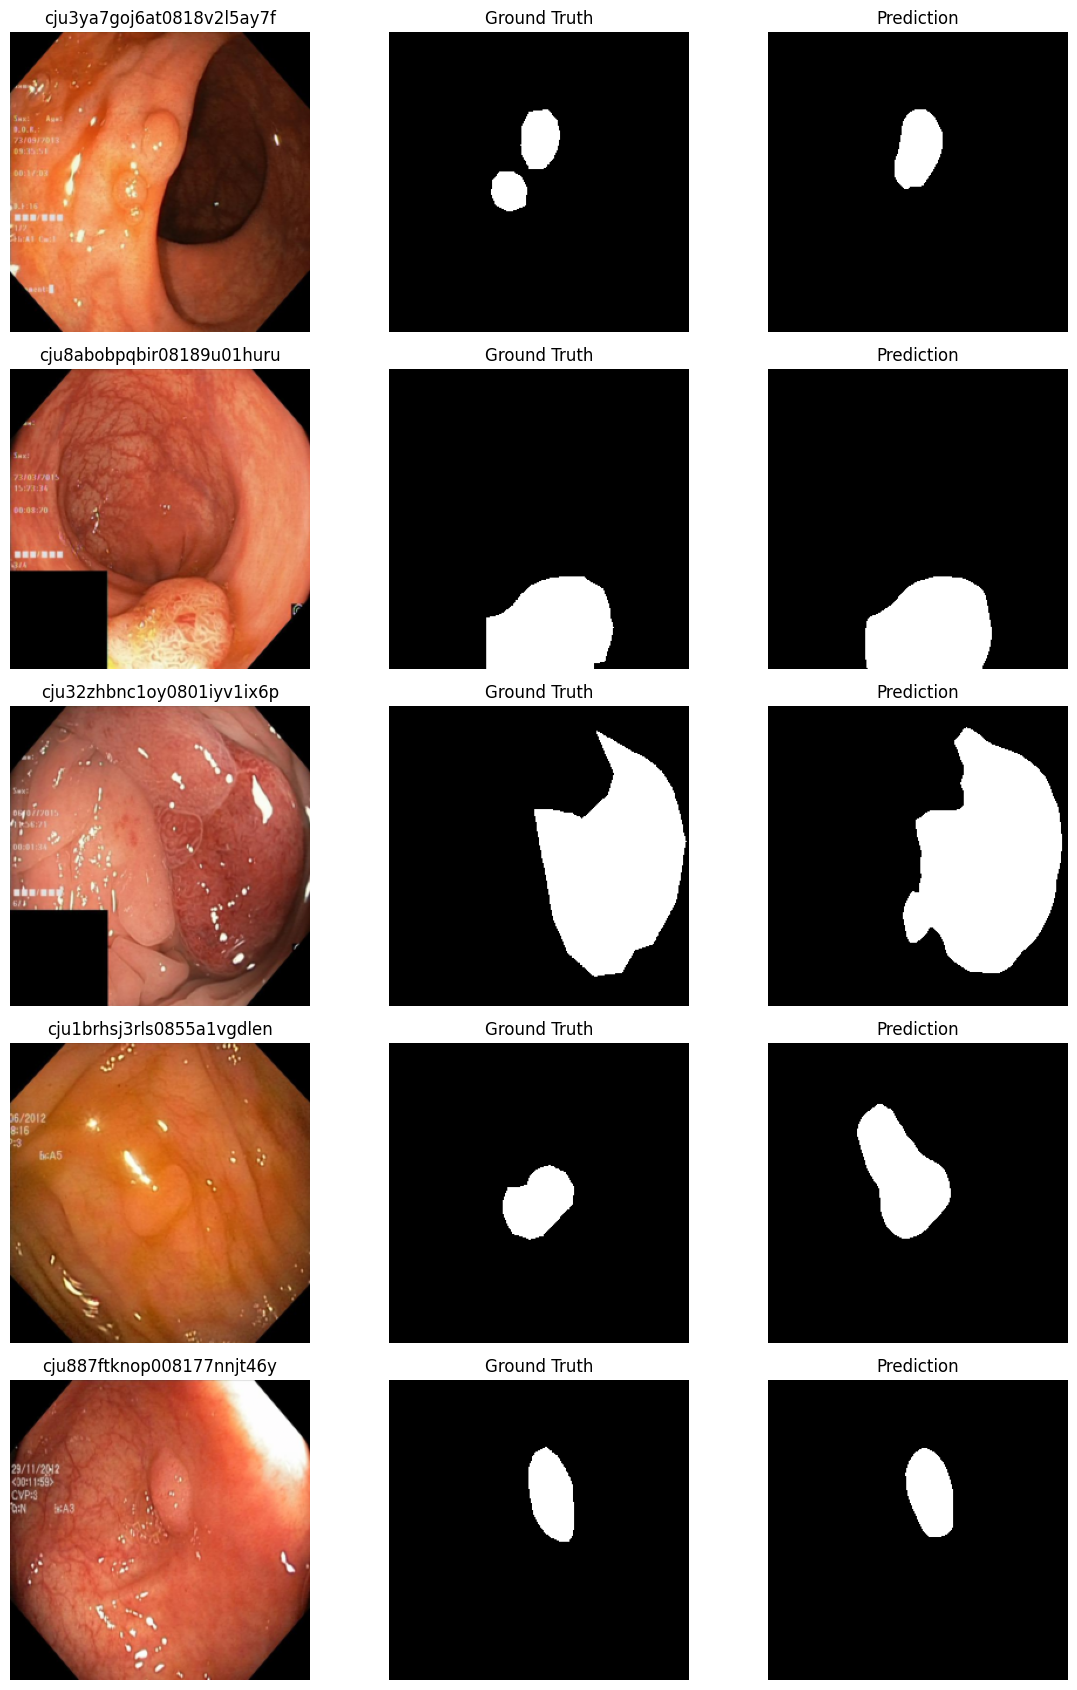

In [11]:
@torch.inference_mode()
def show_predictions(loader, n=5):
    model.eval()
    samples = []
    for images_batch, masks_batch, names_batch in loader:
        for img, mask, name in zip(images_batch, masks_batch, names_batch):
            samples.append((img, mask, str(name)))
            if len(samples) == n:
                break
        if len(samples) == n:
            break
    if not samples:
        raise RuntimeError("Test loader không có dữ liệu.")

    fig, axes = plt.subplots(len(samples), 3, figsize=(12, 3.4 * len(samples)), squeeze=False)
    for row_axes, (img, mask, name) in zip(axes, samples):
        pred = (model(img[None].to(device)).sigmoid()[0, 0] >= 0.5).cpu().numpy()
        rgb = (img * IMAGENET_STD + IMAGENET_MEAN).permute(1, 2, 0).numpy().clip(0, 1)
        row_axes[0].imshow(rgb)
        row_axes[0].set_title(name)
        row_axes[1].imshow(mask[0], cmap="gray", vmin=0, vmax=1)
        row_axes[1].set_title("Ground Truth")
        row_axes[2].imshow(pred, cmap="gray", vmin=0, vmax=1)
        row_axes[2].set_title("Prediction")
        for ax in row_axes:
            ax.axis("off")
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / "test_prediction_examples.png", dpi=150)
    plt.show()

show_predictions(test_loader, n=5)

## 12. Per-image Test Metrics
Dice, IoU, Precision, Recall, TP/FP/FN/TN cho từng ảnh; xuất CSV và đối chiếu lại micro Dice/IoU để phát hiện sai lệch pipeline.

In [12]:
checkpoint_analysis = torch.load(
    BEST_MODEL_PATH, map_location="cpu", weights_only=True
)
model.load_state_dict(checkpoint_analysis["model_state_dict"])
model.to(device).eval()

THRESHOLD = 0.5
analysis_rows = []
analysis_cache = {}

with torch.inference_mode():
    for images_batch, masks_batch, names_batch in test_loader:
        probabilities = model(images_batch.to(device)).sigmoid()
        predictions = probabilities.ge(THRESHOLD).cpu().numpy()[:, 0]
        targets = masks_batch.numpy()[:, 0] >= 0.5

        for i, name in enumerate(names_batch):
            name = str(name)
            gt = targets[i]
            pred = predictions[i]

            tp = int(np.count_nonzero(pred & gt))
            fp = int(np.count_nonzero(pred & ~gt))
            fn = int(np.count_nonzero(~pred & gt))
            tn = int(np.count_nonzero(~pred & ~gt))

            gt_pixels = tp + fn
            pred_pixels = tp + fp
            dice_denominator = 2 * tp + fp + fn
            union = tp + fp + fn

            analysis_rows.append({
                "name": name,
                "dice": (
                    2 * tp / dice_denominator
                    if dice_denominator else 1.0
                ),
                "iou": tp / union if union else 1.0,
                "precision": tp / pred_pixels if pred_pixels else np.nan,
                "recall": tp / gt_pixels if gt_pixels else np.nan,
                "tp": tp,
                "fp": fp,
                "fn": fn,
                "tn": tn,
                "gt_pixels": gt_pixels,
                "pred_pixels": pred_pixels,
                "gt_ratio": gt_pixels / gt.size,
                "touches_border": bool(
                    gt[0].any() or gt[-1].any()
                    or gt[:, 0].any() or gt[:, -1].any()
                ),
            })

            # Lưu ảnh và mask để vẽ lại mà không cần suy luận thêm.
            analysis_cache[name] = {
                "image": (
                    images_batch[i] * IMAGENET_STD + IMAGENET_MEAN
                ).permute(1, 2, 0).numpy().clip(0, 1).copy(),
                "gt": gt.copy(),
                "pred": pred.copy(),
            }

analysis_df = pd.DataFrame(analysis_rows)

assert len(analysis_df) == len(test_dataset), "Chưa đánh giá đủ ảnh test"
assert analysis_df["name"].is_unique, "Tên ảnh test bị trùng"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
analysis_df.to_csv(OUTPUT_DIR / "test_per_image.csv", index=False)

# Tính lại metric gộp để đối chiếu với kết quả notebook hiện tại.
tp_total = int(analysis_df["tp"].sum())
fp_total = int(analysis_df["fp"].sum())
fn_total = int(analysis_df["fn"].sum())

global_denominator = 2 * tp_total + fp_total + fn_total
global_union = tp_total + fp_total + fn_total

analysis_summary = {
    "checkpoint_epoch": int(checkpoint_analysis["epoch"]),
    "threshold": THRESHOLD,
    "test_images": len(analysis_df),
    "global_dice": (
        2 * tp_total / global_denominator
        if global_denominator else 1.0
    ),
    "global_iou": (
        tp_total / global_union if global_union else 1.0
    ),
    "mean_image_dice": float(analysis_df["dice"].mean()),
    "mean_image_iou": float(analysis_df["iou"].mean()),
    "median_image_dice": float(analysis_df["dice"].median()),
}

with open(OUTPUT_DIR / "test_analysis_summary.json", "w") as f:
    json.dump(analysis_summary, f, indent=2)

print(json.dumps(analysis_summary, indent=2))
display(analysis_df.head())

# Xác nhận kết quả tính lại khớp metric Test chính.
assert abs(analysis_summary["global_dice"] - results["test_dice"]) < 1e-6
assert abs(analysis_summary["global_iou"] - results["test_iou"]) < 1e-6
print("Micro metrics cross-check: PASSED")

{
  "checkpoint_epoch": 20,
  "threshold": 0.5,
  "test_images": 100,
  "global_dice": 0.8912178945266501,
  "global_iou": 0.803780914326878,
  "mean_image_dice": 0.8967836549152121,
  "mean_image_iou": 0.8245553466617291,
  "median_image_dice": 0.9377591690987253
}


,name,dice,iou,precision,recall,tp,fp,fn,tn,gt_pixels,pred_pixels,gt_ratio,touches_border
0,cju3ya7goj6at0818v2l5ay7f,0.654842,0.486815,0.677451,0.633695,1403,668,811,62654,2214,2071,0.033783,False
1,cju8abobpqbir08189u01huru,0.988915,0.978073,0.985367,0.992489,7003,104,53,58376,7056,7107,0.107666,True
2,cju32zhbnc1oy0801iyv1ix6p,0.916686,0.846186,0.861489,0.979439,16196,2604,340,46396,16536,18800,0.252319,False
3,cju1brhsj3rls0855a1vgdlen,0.634331,0.464484,0.474042,0.958397,2511,2786,109,60130,2620,5297,0.039978,False
4,cju887ftknop008177nnjt46y,0.955401,0.914609,0.963342,0.947589,2260,86,125,63065,2385,2346,0.036392,False


Micro metrics cross-check: PASSED


## 13. Phân tích theo diện tích polyp và vị trí chạm mép
Nhóm theo tỷ lệ foreground GT và kiểm tra mask thật chạm biên hay không. 
Các ngưỡng kích thước giữ nguyên notebook baseline, không xem là nhãn lâm sàng.

Theo tỷ lệ diện tích mask thật:


,size_group,n,mean_dice,median_dice,mean_iou,mean_recall,mean_precision,precision_defined,recall_defined
0,1-<5%,19,0.8705,0.9385,0.7856,0.8976,0.8690,19,19
1,5-<20%,47,0.9168,0.9551,0.8553,0.9392,0.9070,47,47
2,>=20%,34,0.8838,0.9119,0.8038,0.8436,0.9514,34,34


Theo việc mask thật có chạm mép ảnh hay không:


,touches_border,n,mean_dice,median_dice,mean_iou,mean_recall,mean_precision,precision_defined,recall_defined
0,False,79,0.9095,0.9473,0.8439,0.9255,0.9068,79,79
1,True,21,0.8488,0.8764,0.7519,0.7984,0.9451,21,21


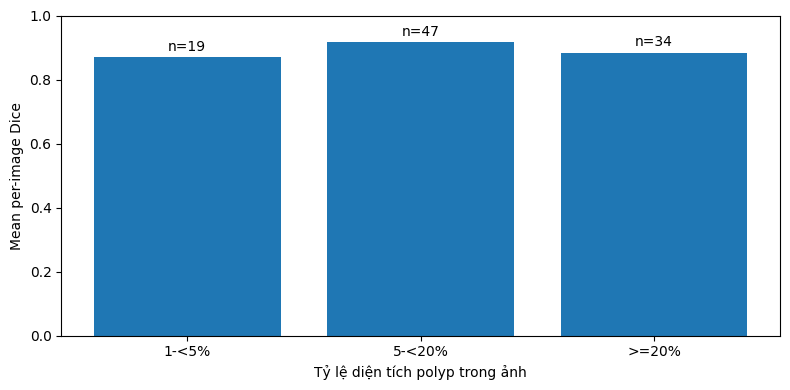

In [13]:
size_labels = ["<1%", "1-<5%", "5-<20%", ">=20%"]
size_categories = ["Empty"] + size_labels

analysis_df["size_group"] = pd.cut(
    analysis_df["gt_ratio"],
    bins=[0, 0.01, 0.05, 0.20, np.inf],
    labels=size_labels,
    right=False,
).astype(object)

analysis_df.loc[
    analysis_df["gt_pixels"] == 0, "size_group"
] = "Empty"

analysis_df["size_group"] = pd.Categorical(
    analysis_df["size_group"],
    categories=size_categories,
    ordered=True,
)

def summarize_groups(column):
    return (
        analysis_df.groupby(column, observed=True)
        .agg(
            n=("name", "size"),
            mean_dice=("dice", "mean"),
            median_dice=("dice", "median"),
            mean_iou=("iou", "mean"),
            mean_recall=("recall", "mean"),
            mean_precision=("precision", "mean"),
            precision_defined=("precision", "count"),
            recall_defined=("recall", "count"),
        )
        .reset_index()
    )

size_summary = summarize_groups("size_group")
border_summary = summarize_groups("touches_border")

size_summary.to_csv(
    OUTPUT_DIR / "test_by_size.csv", index=False
)
border_summary.to_csv(
    OUTPUT_DIR / "test_by_border.csv", index=False
)

print("Theo tỷ lệ diện tích mask thật:")
display(size_summary.round(4))

print("Theo việc mask thật có chạm mép ảnh hay không:")
display(border_summary.round(4))

fig, ax = plt.subplots(figsize=(8, 4))

ax.bar(
    size_summary["size_group"].astype(str),
    size_summary["mean_dice"],
)
ax.set_ylim(0, 1)
ax.set_xlabel("Tỷ lệ diện tích polyp trong ảnh")
ax.set_ylabel("Mean per-image Dice")

for i, row in size_summary.iterrows():
    ax.text(
        i,
        row["mean_dice"] + 0.02,
        f"n={int(row['n'])}",
        ha="center",
    )

fig.tight_layout()
fig.savefig(OUTPUT_DIR / "dice_by_size.png", dpi=150)
plt.show()

## 14. Thống kê các nhóm lỗi trên Test
Nhóm Dice cao/thấp, không phát hiện vùng polyp, không giao GT, low recall và low precision.
**Các nhóm có thể chồng lấn**; đếm lỗi là mô tả định lượng, không tự động chứng minh nguyên nhân gây lỗi.

In [14]:
analysis_df["good_overlap"] = analysis_df["dice"] >= 0.8
analysis_df["poor_overlap"] = analysis_df["dice"] < 0.5

analysis_df["no_prediction"] = (
    (analysis_df["gt_pixels"] > 0)
    & (analysis_df["pred_pixels"] == 0)
)

analysis_df["no_overlap"] = (
    (analysis_df["gt_pixels"] > 0)
    & (analysis_df["tp"] == 0)
)

analysis_df["low_recall"] = (
    (analysis_df["gt_pixels"] > 0)
    & (analysis_df["recall"] < 0.5)
)

analysis_df["low_precision"] = (
    (analysis_df["pred_pixels"] > 0)
    & (analysis_df["precision"] < 0.5)
)

conditions = {
    "Dice >= 0.8": "good_overlap",
    "Dice < 0.5": "poor_overlap",
    "Có polyp nhưng không dự đoán vùng nào": "no_prediction",
    "Không có pixel dự đoán giao với polyp thật": "no_overlap",
    "Bỏ sót hơn 50% số pixel polyp": "low_recall",
    "Hơn 50% pixel dự đoán là nền theo GT": "low_precision",
}

frequency_df = pd.DataFrame([
    {
        "condition": label,
        "images": int(analysis_df[column].sum()),
        "percent_of_test": 100 * analysis_df[column].mean(),
    }
    for label, column in conditions.items()
])

frequency_df.to_csv(
    OUTPUT_DIR / "test_error_frequency.csv", index=False
)

# Cập nhật bảng từng ảnh với các nhóm và nhãn lỗi vừa thêm.
analysis_df.to_csv(
    OUTPUT_DIR / "test_per_image.csv", index=False
)

display(frequency_df.round(2))

print(
    "Các nhóm có thể chồng lấn; "
    "tỷ lệ đều tính trên toàn bộ tập test."
)

,condition,images,percent_of_test
0,Dice >= 0.8,84,84.0
1,Dice < 0.5,0,0.0
2,Có polyp nhưng không dự đoán vùng nào,0,0.0
3,Không có pixel dự đoán giao với polyp thật,0,0.0
4,Bỏ sót hơn 50% số pixel polyp,2,2.0
5,Hơn 50% pixel dự đoán là nền theo GT,1,1.0


Các nhóm có thể chồng lấn; tỷ lệ đều tính trên toàn bộ tập test.


## 15. 5 trường hợp tốt nhất, 5 kém nhất — Error Map
Ảnh đầu vào, Ground Truth, Prediction và overlay **TP xanh lá / FP đỏ / FN xanh dương**.

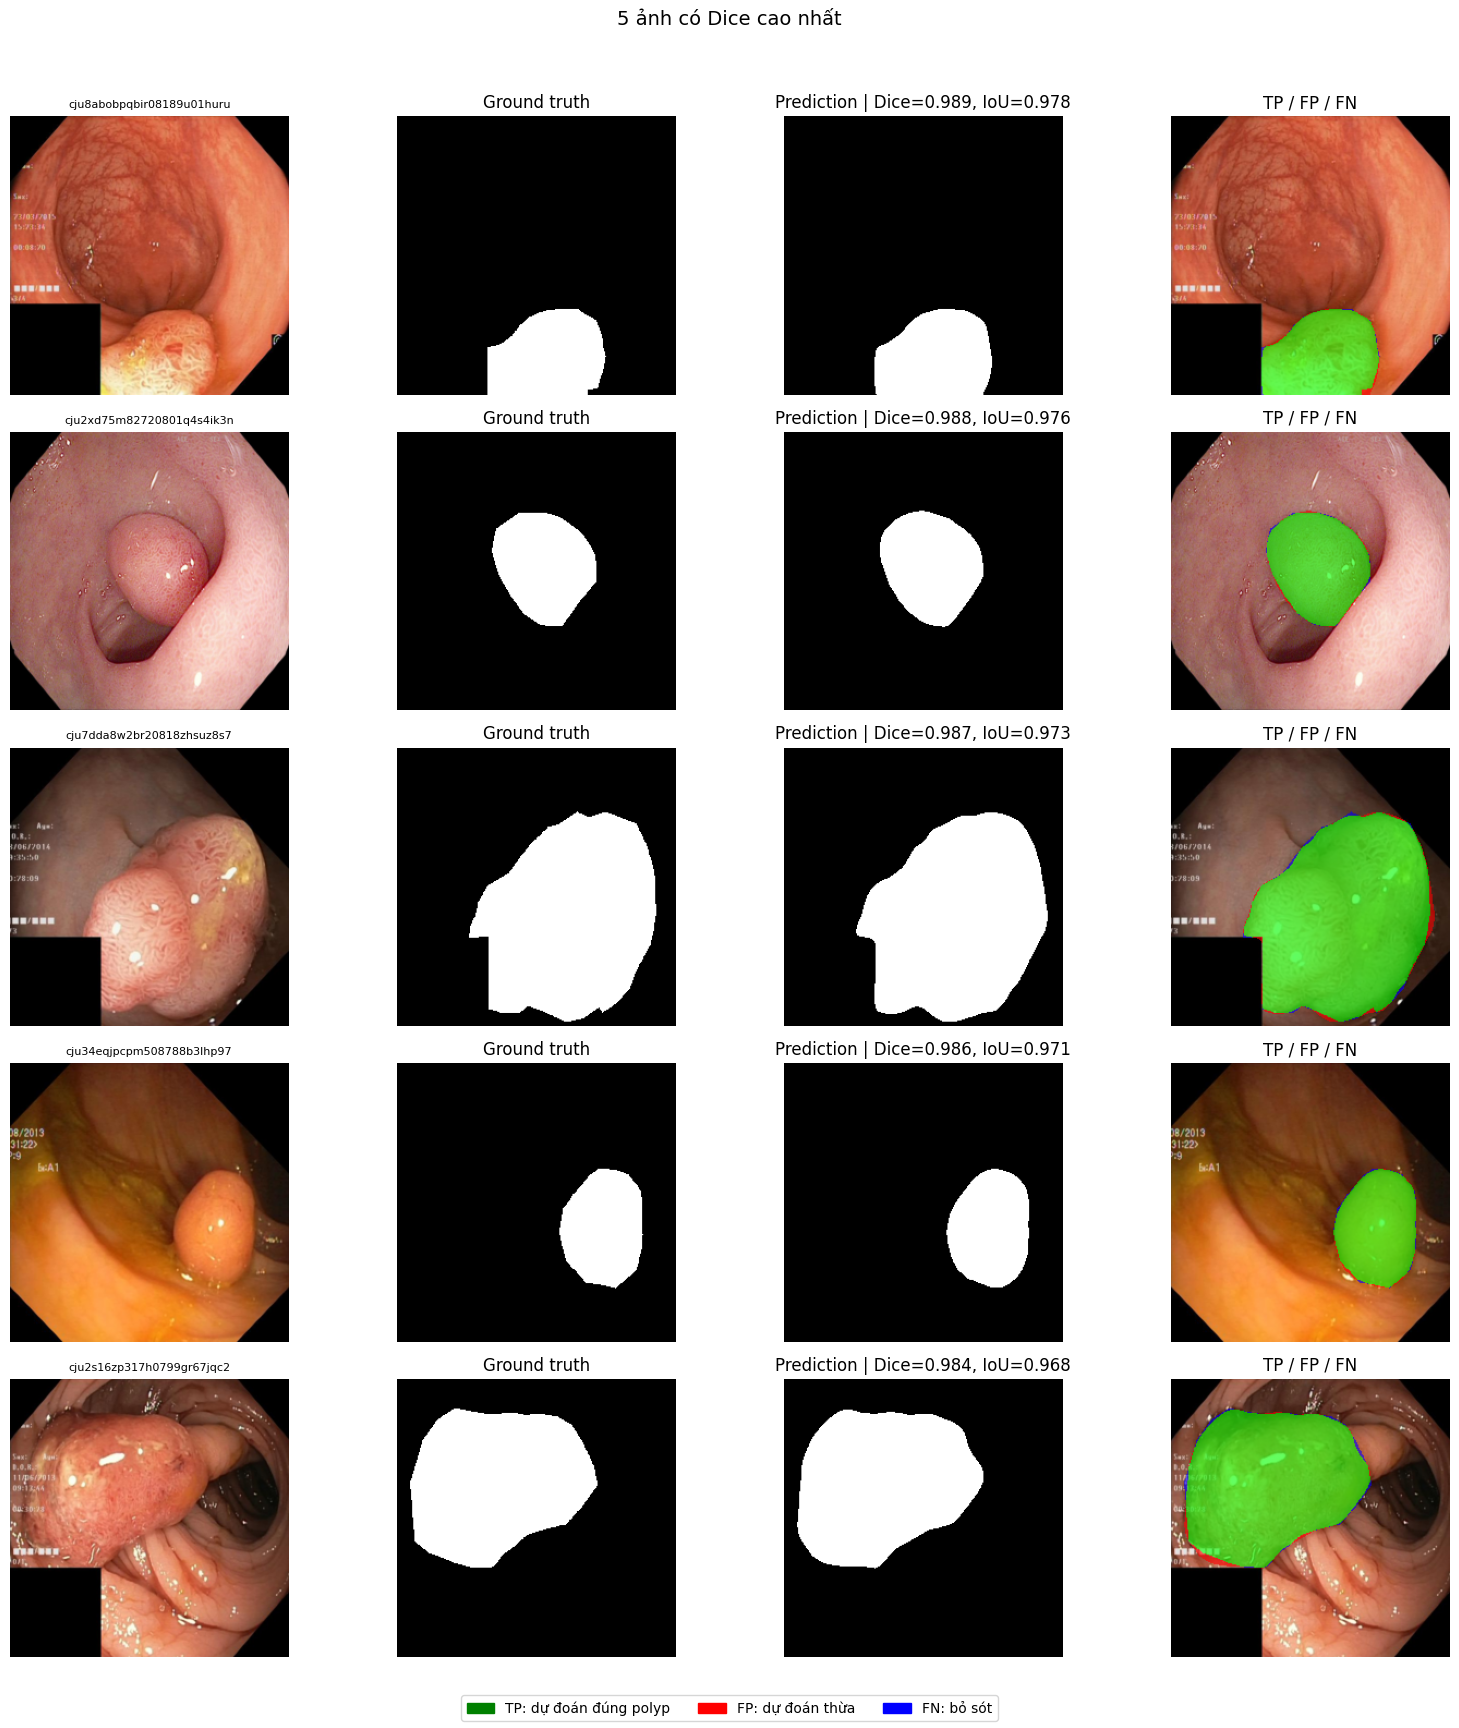

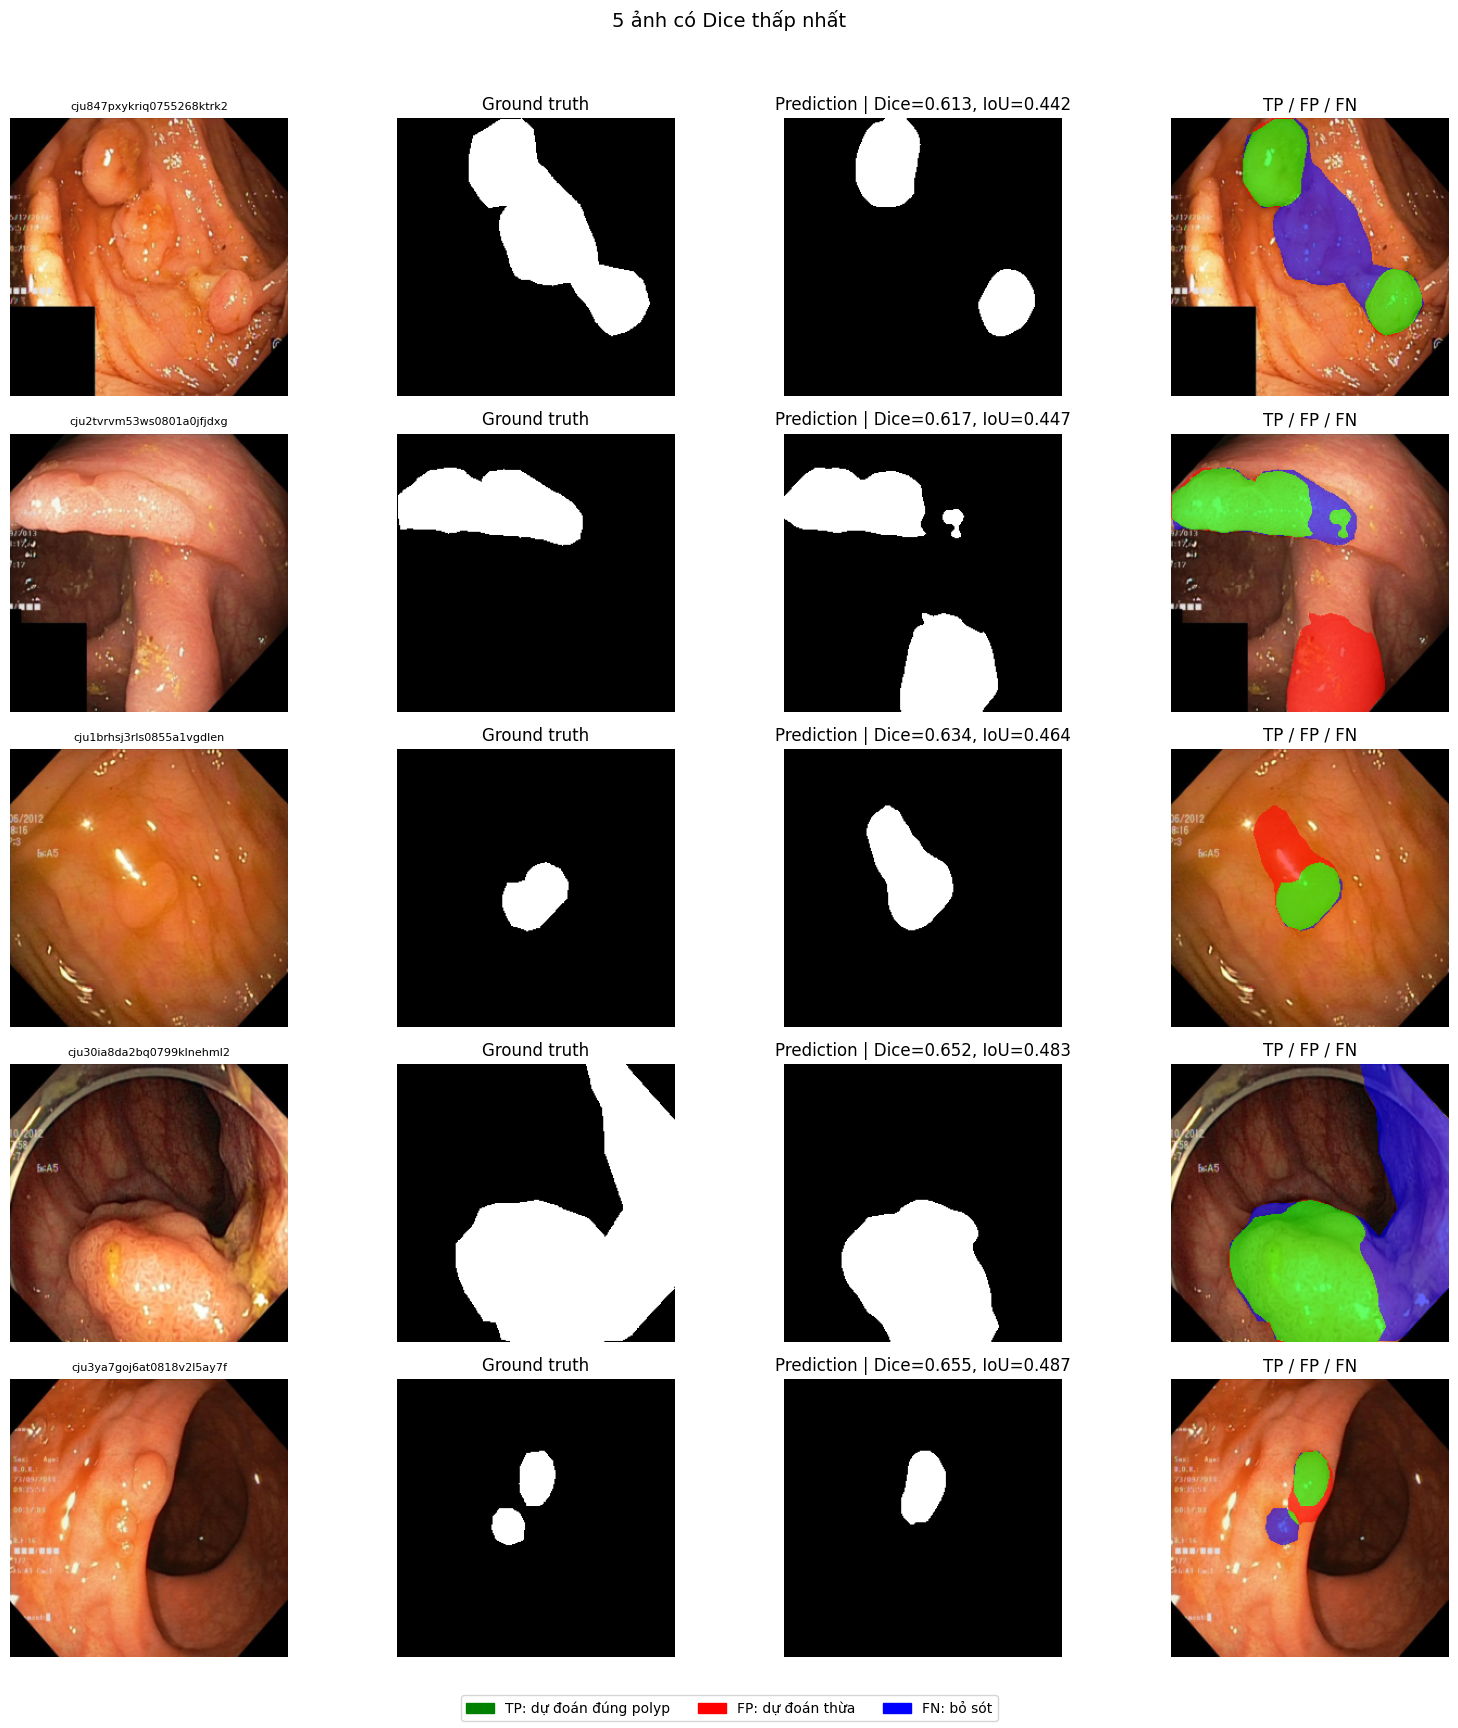

In [15]:
from matplotlib.patches import Patch

def show_analysis_cases(frame, title, filename, n=5):
    selected = frame.head(n)

    if selected.empty:
        print("Không có ảnh cho nhóm:", title)
        return

    fig, axes = plt.subplots(
        len(selected),
        4,
        figsize=(16, 3.5 * len(selected)),
        squeeze=False,
    )

    for row_axes, (_, row) in zip(axes, selected.iterrows()):
        item = analysis_cache[row["name"]]

        image = np.clip(item["image"], 0, 1)
        gt = item["gt"]
        pred = item["pred"]

        overlay = image.copy()

        for region, color in [
            (pred & gt, [0, 1, 0]),
            (pred & ~gt, [1, 0, 0]),
            (~pred & gt, [0, 0, 1]),
        ]:
            overlay[region] = (
                0.4 * image[region]
                + 0.6 * np.array(color)
            )

        row_axes[0].imshow(image)
        row_axes[0].set_title(row["name"], fontsize=8)

        row_axes[1].imshow(
            gt, cmap="gray", vmin=0, vmax=1
        )
        row_axes[1].set_title("Ground truth")

        row_axes[2].imshow(
            pred, cmap="gray", vmin=0, vmax=1
        )
        row_axes[2].set_title(
            f"Prediction | Dice={row['dice']:.3f}, "
            f"IoU={row['iou']:.3f}"
        )

        row_axes[3].imshow(overlay)
        row_axes[3].set_title("TP / FP / FN")

        for ax in row_axes:
            ax.axis("off")

    fig.suptitle(title, fontsize=14)

    fig.legend(
        handles=[
            Patch(color="green", label="TP: dự đoán đúng polyp"),
            Patch(color="red", label="FP: dự đoán thừa"),
            Patch(color="blue", label="FN: bỏ sót"),
        ],
        loc="lower center",
        ncol=3,
    )

    fig.tight_layout(rect=[0, 0.03, 1, 0.96])
    fig.savefig(
        OUTPUT_DIR / filename,
        dpi=150,
        bbox_inches="tight",
    )
    plt.show()


show_analysis_cases(
    analysis_df.sort_values(
        ["dice", "name"], ascending=[False, True]
    ),
    "5 ảnh có Dice cao nhất",
    "test_best_cases.png",
)

show_analysis_cases(
    analysis_df.sort_values(
        ["dice", "name"], ascending=[True, True]
    ),
    "5 ảnh có Dice thấp nhất",
    "test_worst_cases.png",
)

## 16. Tệp kết quả

Tất cả lưu trong `/kaggle/working/unet_resnet34_kvasir/`:
- `best_unet_resnet34_kvasir.pt` — best checkpoint theo Validation Dice.
- `training_history.csv`, `training_curves.png` — lịch sử training.
- `split_manifest.csv` — ID train/val/test.
- `test_metrics.json` — Test Loss, micro Dice/IoU.
- `test_per_image.csv`, `test_analysis_summary.json` — per-image & macro/micro metrics.
- `test_by_size.csv`, `test_by_border.csv`, `dice_by_size.png` — stratified error analysis.
- `test_error_frequency.csv`, `test_best_cases.png`, `test_worst_cases.png` — thống kê và trực quan hóa lỗi.
- `test_prediction_examples.png` — 5 dự đoán mẫu.

**Phân biệt nguồn gốc:** pretrained encoder ResNet34 từ torchvision; decoder tự cài theo `unet_resnet34.py`.